In [1]:
from collections import Counter
import geopandas as gpd
from glob import glob
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from scipy.stats import kendalltau, pearsonr
import seaborn as sns

In [2]:
acc_cols = ['gravity_BEDS', '2sfca_30_BEDS', '2sfca_60_BEDS', 'e2sfca_30_BEDS', 'e2sfca_60_BEDS',
            'g2sfca10_BEDS', 'g2sfca20_BEDS', '3sfca_BEDS', 'raam30_BEDS', 'raam60_BEDS']
acc_titles = {
    'gravity_BEDS': "Gravity",
    '2sfca_30_BEDS': "2SFCA (30min)",
    '2sfca_60_BEDS': "2SFCA (60min)",
    'e2sfca_30_BEDS': "E2SFCA (30min)",
    'e2sfca_60_BEDS': "E2SFCA (60 min)",
    'g2sfca10_BEDS': r"G2SFCA ($\sigma$=10)",
    'g2sfca20_BEDS': r"G2SFCA ($\sigma$=20)",
    '3sfca_BEDS': "3SFCA",
    'raam30_BEDS': r"RAAM ($\tau$=30)",
    'raam60_BEDS': r"RAAM ($\tau$=60)"
}
res_col = "Cost_2"

In [3]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
# drop rows with nan values
acc = acc.dropna(subset=acc_cols)
print(len(acc))
acc.head()

1315


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [4]:
experiment_paths_oc = glob("../outputs/OnlyCars/*")
experiment_paths_nv = glob("../outputs/NoVeh/*")
experiment_paths = {'onlycars': experiment_paths_oc, 'noveh': experiment_paths_nv}

In [5]:
# params tested
cost_funcs = ["raam", "gravity"]
noveh = ['onlycars', 'noveh']
timesteps = [10, 15, 20, 25, 30]
topK = [1, 2, 3, 4, 5]
numAgents = [1000, 100, 10, 1]

In [6]:
# quick sanity check
cf_counter, ts_counter, tk_counter, na_counter = Counter(), Counter(), Counter(), Counter()
for k, v in experiment_paths.items():
    for path in v:
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    #     print(cf, ts, tk, na)
        cf_counter[cf] +=1
        ts_counter[ts] +=1
        tk_counter[tk] +=1
        na_counter[na] +=1
# you should see even numbers for all parameter options
cf_counter, ts_counter, tk_counter, na_counter

(Counter({'gravity': 1000, 'raam': 1000}),
 Counter({30: 400, 10: 400, 20: 400, 15: 400, 25: 400}),
 Counter({2: 400, 5: 400, 3: 400, 4: 400, 1: 400}),
 Counter({100: 500, 1: 500, 10: 500, 1000: 500}))

In [7]:
def calculate_corrs(acc_cols, res_col, acc):
    experiment_corr = dict()
    for k, v in experiment_paths.items():
        for path in v:
            for acc_corr in acc_cols:
                # load the parameter json
                param_path = os.path.join(path, "parameters.json")
                param_file = open(param_path)
                params = json.load(param_file)
                cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
                # load the data
                results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
                results.index = results.index.map(str)
                # join with accessibility data on GEOID
                # join the last time step's cost
                merged = pd.merge(acc[[acc_corr]], results[[res_col]], left_index=True, right_index=True)
            #     print(len(merged))
                corr_res = kendalltau(merged[acc_corr], merged[res_col])
                try:
                    experiment_corr[acc_corr, k, cf, ts, tk, na].append(corr_res.correlation)
                except:
                    experiment_corr[acc_corr, k, cf, ts, tk, na] = [corr_res.correlation]
    return experiment_corr

In [8]:
experiment_corr = calculate_corrs(acc_cols, res_col, acc)
# experiment_corr

In [9]:
experiment_corr

{('gravity_BEDS',
  'onlycars',
  'gravity',
  30,
  2,
  100): [np.float64(-0.7193349190640715), np.float64(-0.7200155100670752), np.float64(-0.7199113379747787), np.float64(-0.7204970166270234), np.float64(-0.7194969645409771)],
 ('2sfca_30_BEDS',
  'onlycars',
  'gravity',
  30,
  2,
  100): [np.float64(-0.3011733625373244), np.float64(-0.30169223157345265), np.float64(-0.30145364447201867), np.float64(-0.30178951951772676), np.float64(-0.3015578815551695)],
 ('2sfca_60_BEDS',
  'onlycars',
  'gravity',
  30,
  2,
  100): [np.float64(-0.33838027393480047), np.float64(-0.33881405530095327), np.float64(-0.3385774472830517), np.float64(-0.338932359309904), np.float64(-0.3385528006145203)],
 ('e2sfca_30_BEDS',
  'onlycars',
  'gravity',
  30,
  2,
  100): [np.float64(-0.48243428756254225), np.float64(-0.4828371457764688), np.float64(-0.4836474927585051), np.float64(-0.4832492650987616), np.float64(-0.48291818047467244)],
 ('e2sfca_60_BEDS',
  'onlycars',
  'gravity',
  30,
  2,
  100): 

In [10]:
method_corr_dict = dict()
for a in acc_cols:
    method_corr_dict[a] = []
for (acc_corr, k, cf, ts, tk, na), v in experiment_corr.items():
    if cf != 'raam':
        method_corr_dict[acc_corr].append(v)

In [17]:
method_corr_dict

{'gravity_BEDS': [[np.float64(-0.7193349190640715),
   np.float64(-0.7200155100670752),
   np.float64(-0.7199113379747787),
   np.float64(-0.7204970166270234),
   np.float64(-0.7194969645409771)],
  [np.float64(-0.7336967781886787),
   np.float64(-0.7337963204102065),
   np.float64(-0.7339352165332684),
   np.float64(-0.7340092944655682),
   np.float64(-0.7335347327117732)],
  [np.float64(-0.7467067150488161),
   np.float64(-0.7464104033196173),
   np.float64(-0.7469960819718618),
   np.float64(-0.7469127442980248),
   np.float64(-0.7471650722549206)],
  [np.float64(-0.6449420046940699),
   np.float64(-0.6449420046940699),
   np.float64(-0.6449420046940699),
   np.float64(-0.6449420046940699),
   np.float64(-0.6449420046940699)],
  [np.float64(-0.764904422105318),
   np.float64(-0.7637423245423661),
   np.float64(-0.7637538992192879),
   np.float64(-0.7635617595823856),
   np.float64(-0.7629598763824503)],
  [np.float64(-0.6416100033922028),
   np.float64(-0.6416100033922028),
   np.fl

In [12]:
dict_for_df = []
for k, v in method_corr_dict.items():
    for corr in v:
        for run in corr:
            if "raam" not in k:
                dict_for_df.append([-run, acc_titles[k]])
            else:
                dict_for_df.append([run, acc_titles[k]])

In [13]:
labels = "Acc"
values = "Kendall's Tau"

x = pd.DataFrame(dict_for_df, columns=[values, labels])
print(len(x))
df = x
df.head()

10000


,Kendall's Tau,Acc
0,0.719335,Gravity
1,0.720016,Gravity
2,0.719911,Gravity
3,0.720497,Gravity
4,0.719497,Gravity


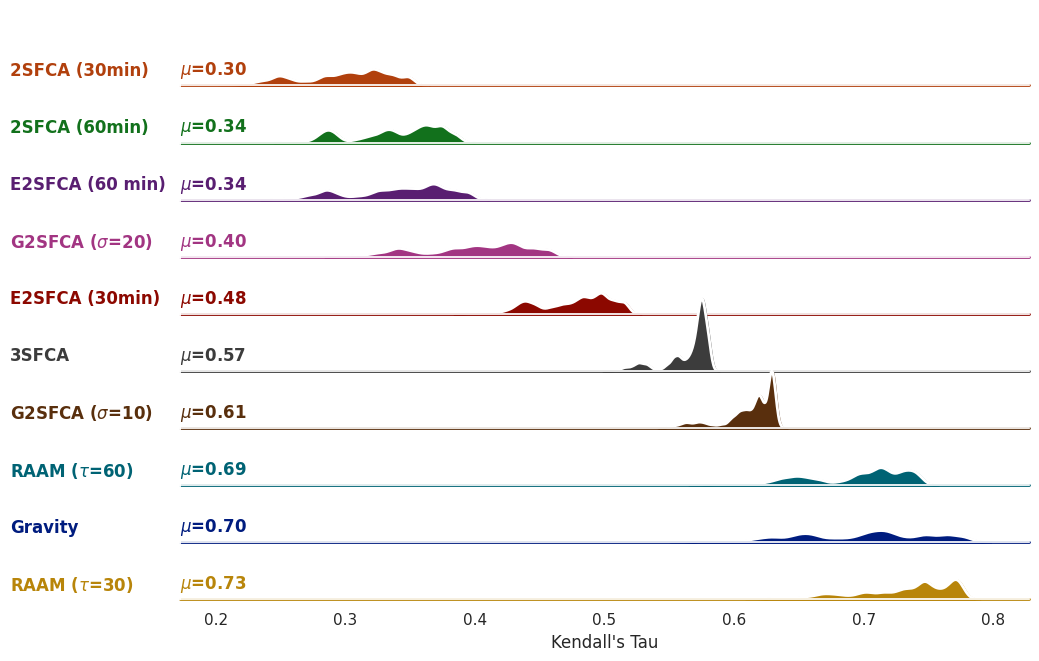

In [14]:
# Create the data
# rs = np.random.RandomState(1979)
# x = rs.randn(500)
# g = np.tile(list("ABCDEFGHIJ"), 50)
# df = pd.DataFrame(dict(x=x, g=g))
# m = df.g.map(ord)
# df["x"] += m
sns.set_theme(style="dark", rc={"axes.facecolor": (0, 0, 0, 0)})
# sns.set(rc={'figure.figsize':(12, 8)})


grp_order = df.groupby(labels)[values].agg('mean').sort_values().index

# Initialize the FacetGrid object
# pal = sns.cubehelix_palette(len(labels), rot=-.25, light=.7)
pal = sns.color_palette("dark", 10)
g = sns.FacetGrid(df, row=labels, hue=labels, aspect=15, height=.7, palette=pal, row_order=grp_order)

# Draw the densities in a few steps
g.map(sns.kdeplot, values,
      bw_adjust=.5, clip_on=False,
      fill=True, alpha=1, linewidth=1.5)
g.map(sns.kdeplot, values, clip_on=False, color="w", lw=2, bw_adjust=.5)

# passing color=None to refline() uses the hue mapping
g.refline(y=0, linewidth=2, linestyle="-", color=None, clip_on=False)


# Define and use a simple function to label the plot in axes coordinates
def label(x, color, label):
    ax = plt.gca()
    ax.text(-.2, .2, label, fontweight="bold", color=color,
            ha="left", va="center", transform=ax.transAxes)

g.map(label, values)

# Define and use a simple function to label the plot in axes coordinates
def label_mean(x, color, label):
    ax = plt.gca()
    ax.text(0, .2, r"$\mu$=" + f"{np.mean(x):.2f}", fontweight="bold", color=color,
            ha="left", va="center", transform=ax.transAxes)


g.map(label_mean, values)

# Set the subplots to overlap
g.figure.subplots_adjust(hspace=-.25)

# Remove axes details that don't play well with overlap
g.set_titles("")
g.set(yticks=[], ylabel="")

In [16]:
g.savefig("../figs/GravityKDEPlot.png")